# Задание III. Регуляризация и ошибки данных

Матрица $A$ усредняет соседние компоненты вектора. Исследуем восстановление исходного сигнала по возмущённой правой части и сравним два штрафа Тихонова.

На сетке $t_i=(i-1)/(m-1)$, $i=1,\ldots,m$, $m=80$ зададим

$$
k_{ij}=\exp\left(-\frac{(t_i-t_j)^2}{2\sigma^2}\right),\qquad
 a_{ij}=\frac{k_{ij}}{\sum_{\ell=1}^m k_{i\ell}},\qquad \sigma=0.025,
$$

$$
x_i^*=0.2+\exp\left(-\frac{(t_i-0.30)^2}{2(0.04)^2}\right)
+0.7\exp\left(-\frac{(t_i-0.72)^2}{2(0.07)^2}\right),\qquad b_0=Ax^*.
$$

Возмущения направлены вдоль $\xi_i=\sin(17i)+\cos(31i)$ и $\zeta_i=\sin(23i)+\cos(11i)$. Аргументы заданы в радианах. Для каждого $\theta\in\{10^{-4},10^{-2}\}$ используем

$$
b^{(1)}=b_0+\theta\|b_0\|_2\frac{\xi}{\|\xi\|_2},\qquad
b^{(2)}=b_0+\theta\|b_0\|_2\frac{\zeta}{\|\zeta\|_2}.
$$

По $b^{(1)}$ находим решение, по $b^{(2)}$ выбираем параметр. Все исходные данные готовим один раз в `float64` и используем во всём опыте. Реализации МНК и расширенной системы находятся в `src/mnk/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray

for _cand in (Path.cwd() / "src", Path.cwd().parent / "src", Path("src")):
    if _cand.is_dir():
        sys.path.insert(0, str(_cand.resolve()))
        break

from decomps.qr import qr_factor
from mnk.lstsq import lstsq
from mnk.tikhonov import tikhonov
from solvers.qr_solve import qr_solve
from solvers.upper_solve import upper_solve

M = 80
DELTA = 0.025
ETAS = [1e-4, 1e-2]
LAMBDAS = [10 ** (-6 + k / 4) for k in range(25)]

In [2]:
def text_table(headers, rows):
    columns = [[str(h)] + [str(row[j]) for row in rows] for j, h in enumerate(headers)]
    widths = [max(len(cell) for cell in column) for column in columns]

    lines = []
    for i in range(len(rows) + 1):
        values = [
            column[i].ljust(w) if j == 0 else column[i].rjust(w)
            for j, (column, w) in enumerate(zip(columns, widths))
        ]
        lines.append("  ".join(values))
    lines.insert(1, "  ".join("-" * w for w in widths))
    return "\n".join(lines)

In [3]:
t = np.linspace(0, 1, M, dtype=np.float64)
indices = np.arange(1, M + 1, dtype=np.float64)
K = np.exp(-((t[:, None] - t[None, :]) ** 2) / (2 * DELTA**2))
A = K / K.sum(axis=1, keepdims=True)
x_star = (
    0.2
    + np.exp(-((t - 0.30) ** 2) / (2 * 0.04**2))
    + 0.7 * np.exp(-((t - 0.72) ** 2) / (2 * 0.07**2))
)
b0 = A @ x_star
xi = np.sin(17 * indices) + np.cos(31 * indices)
zeta = np.sin(23 * indices) + np.cos(11 * indices)
thetas = np.array(ETAS, dtype=np.float64)
b1 = b0 + thetas[:, None] * np.linalg.norm(b0) * xi / np.linalg.norm(xi)
b2 = b0 + thetas[:, None] * np.linalg.norm(b0) * zeta / np.linalg.norm(zeta)
x0 = np.zeros(M, dtype=np.float64)
I = np.eye(M, dtype=np.float64)
D = np.diff(I, axis=0)
PENALTIES = ("I", "D")
gammas = (I, D)
lambdas = np.array(LAMBDAS, dtype=np.float64)

print("A:", A.shape, A.dtype, "D:", D.shape, D.dtype)
print("max |A 1 - 1| =", np.max(np.abs(A @ np.ones(M) - 1)))
print(
    text_table(
        ["theta", "||b1-b0|| / ||b0||", "||b2-b0|| / ||b0||"],
        [
            [
                f"{theta:.0e}",
                f"{np.linalg.norm(b1[i] - b0) / np.linalg.norm(b0):.6e}",
                f"{np.linalg.norm(b2[i] - b0) / np.linalg.norm(b0):.6e}",
            ]
            for i, theta in enumerate(thetas)
        ],
    )
)

A: (80, 80) float64 D: (79, 80) float64
max |A 1 - 1| = 2.220446049250313e-16
theta  ||b1-b0|| / ||b0||  ||b2-b0|| / ||b0||
-----  ------------------  ------------------
1e-04        1.000000e-04        1.000000e-04
1e-02        1.000000e-02        1.000000e-02


## 1. Без регуляризации

Построим $x^*$, $b_0$, $b^{(1)}$, $b^{(2)}$ и решим $Ax=b^{(1)}$ через QR. Найдём относительную невязку и отклонение от $x^*$.

Для показателя обусловленности используем определение из лабораторной

$$
\chi_F(A)=\|A\|_F\sqrt{\sum_{j=1}^m\|z_j\|_2^2},\qquad Rz_j=e_j,
$$

где $R$ получена из QR-разложения. Последовательно решаем треугольные системы по одному столбцу. Полную обратную матрицу хранить не требуется.

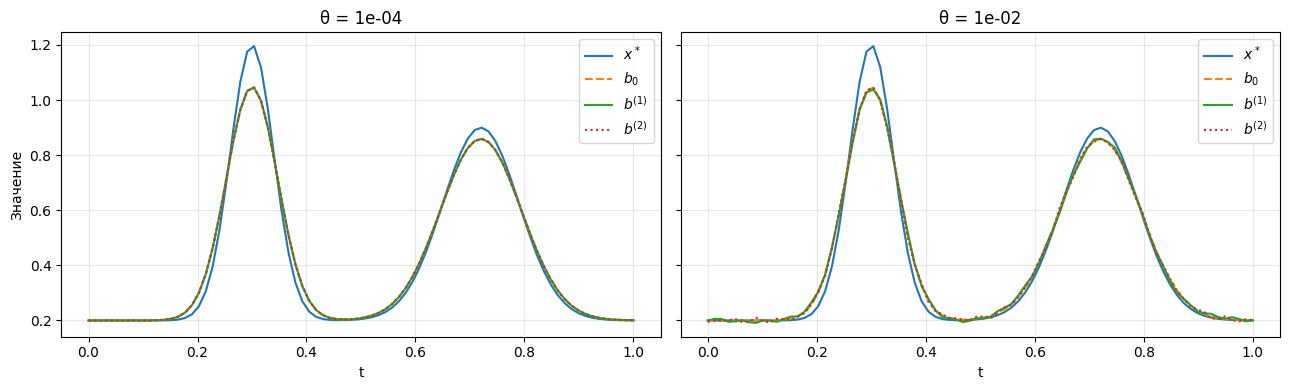

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for i, theta in enumerate(thetas):
    axes[i].plot(t, x_star, label=r"$x^*$")
    axes[i].plot(t, b0, "--", label=r"$b_0$")
    axes[i].plot(t, b1[i], label=r"$b^{(1)}$")
    axes[i].plot(t, b2[i], ":", label=r"$b^{(2)}$")
    axes[i].set_title(f"θ = {theta:.0e}")
    axes[i].set_xlabel("t")
    axes[i].grid(True, alpha=0.3)
    axes[i].legend()
axes[0].set_ylabel("Значение")
plt.tight_layout()
plt.show()

In [5]:
def chi_f(A: NDArray) -> np.floating:
    F, _ = qr_factor(A)
    m = A.shape[1]
    total_sq = A.dtype.type(0)
    for j in range(m):
        e = np.zeros(m, dtype=A.dtype)
        e[j] = 1
        z = upper_solve(F[:m], e)
        total_sq += np.sum(z**2)
    return np.linalg.norm(A, ord="fro") * np.sqrt(total_sq)


F, tau = qr_factor(A)
x_unreg = np.array([qr_solve(F, tau, b) for b in b1])
unreg_errors = np.linalg.norm(x_unreg - x_star, axis=1) / np.linalg.norm(x_star)
unreg_residuals = np.linalg.norm(x_unreg @ A.T - b1, axis=1) / np.linalg.norm(
    b1, axis=1
)
chi_A = chi_f(A)

print(f"chi_F(A) = {chi_A:.6e}")
print(
    text_table(
        ["theta", "отн. невязка", "отн. ошибка"],
        [
            [f"{theta:.0e}", f"{unreg_residuals[i]:.6e}", f"{unreg_errors[i]:.6e}"]
            for i, theta in enumerate(thetas)
        ],
    )
)

chi_F(A) = 4.629248e+08
theta  отн. невязка   отн. ошибка
-----  ------------  ------------
1e-04  3.537378e-16  8.305112e-01
1e-02  8.677380e-15  8.305112e+01


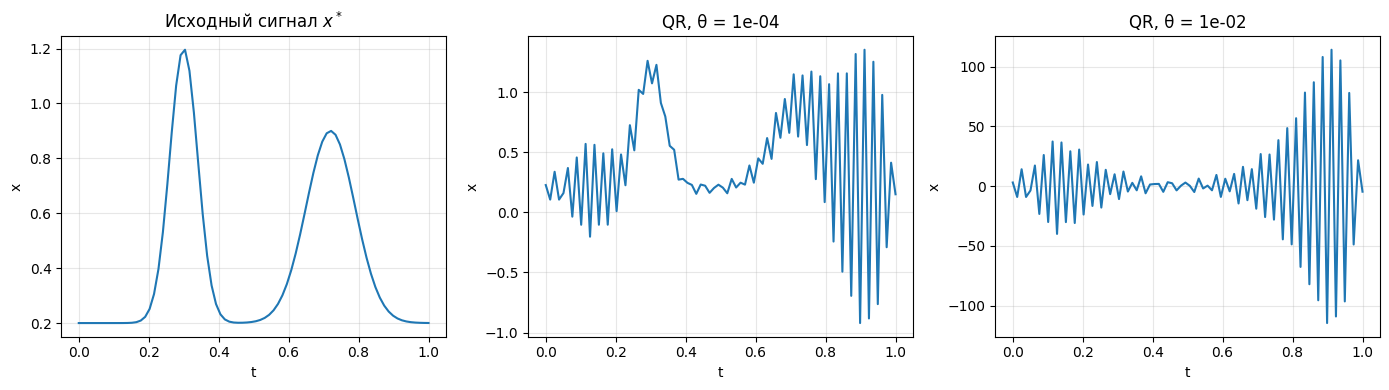

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(t, x_star)
axes[0].set_title(r"Исходный сигнал $x^*$")
for i, theta in enumerate(thetas):
    axes[i + 1].plot(t, x_unreg[i])
    axes[i + 1].set_title(f"QR, θ = {theta:.0e}")
for ax in axes:
    ax.set_xlabel("t")
    ax.set_ylabel("x")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Сглаживание уменьшило высоту первого узкого пика. На графиках $b_0$, $b^{(1)}$ и $b^{(2)}$ при малом $\theta$ почти совпадают, хотя их различия заметно влияют на восстановление.

Получено $\chi_F(A)\approx4.63\cdot10^8$. Без регуляризации относительные ошибки равны $0.831$ при $\theta=10^{-4}$ и $83.1$ при $\theta=10^{-2}$. Стократное увеличение возмущения привело примерно к стократному увеличению ошибки. В решениях появились частые колебания.

При этом относительные невязки имеют порядок $10^{-16}$ и $10^{-14}$. QR хорошо решает систему с возмущённой правой частью. Восстановление исходного $x^*$ чувствительно к этим возмущениям из-за плохой обусловленности $A$.

## 2. Два штрафа

Сравним $\Gamma=I_m$ и матрицу первых разностей $D$, для которой

$$
\|Dx\|_2^2=\sum_{i=1}^{m-1}(x_{i+1}-x_i)^2.
$$

Малую $\|x\|_2$ имеют векторы с небольшими компонентами. Штраф $I_m$ уменьшает амплитуды пиков и постоянную составляющую.

Малая $\|Dx\|_2$ означает небольшие изменения между соседними отсчётами. Уровень постоянного фона на эту величину не влияет. Из $Dx=0$ следует $x_{i+1}=x_i$ для всех $i$, поэтому

$$
\operatorname{Ker}(D)=\{c\mathbf{1}_m:c\in\mathbb R\}.
$$

По построению $A\mathbf{1}_m=\mathbf{1}_m$. Если $x=c\mathbf{1}_m$ также принадлежит $\operatorname{Ker}(A)$, то $Ax=c\mathbf{1}_m=0$, откуда $c=0$. Значит,

$$
\operatorname{Ker}(A)\cap\operatorname{Ker}(D)=\{0\}.
$$

При $\lambda>0$ для любого ненулевого $z$ имеем

$$
z^\top(A^\top A+\lambda^2\Gamma^\top\Gamma)z
=\|Az\|_2^2+\lambda^2\|\Gamma z\|_2^2>0.
$$

Для $\Gamma=I_m$ это следует из $\|z\|_2>0$. Для $\Gamma=D$ положительность следует из доказанного пересечения ядер. Поэтому расширенная матрица имеет полный столбцовый ранг, и регуляризованное решение единственно для обоих штрафов.

## 3. Перебор параметра

Возьмём $\lambda_k=10^{-6+k/4}$, $k=0,\ldots,24$. Для каждой пары $\theta$ и $\Gamma$ подготовим расширенную систему функцией `tikhonov` с $x_0=0$ и решим её через `lstsq(..., method="qr")`.

Сохраним $\|Ax_\lambda-b^{(1)}\|_2$, $\|\Gamma x_\lambda\|_2$ и

$$
E(\lambda)=\frac{\|Ax_\lambda-b^{(2)}\|_2}{\|b^{(2)}\|_2}.
$$

Невязку измеряем по исходной матрице $A$ и первой правой части. В расширенной системе также учитывается штраф. Точное решение $x^*$ в переборе и выборе по $E$ не участвует.

In [7]:
def regularization_path(
    A: NDArray, b1: NDArray, b2: NDArray, Gamma: NDArray, x0: NDArray, lambdas: NDArray
) -> tuple[NDArray, NDArray, NDArray, NDArray]:
    xs = np.empty((len(lambdas), A.shape[1]), dtype=A.dtype)
    residuals = np.empty(len(lambdas), dtype=A.dtype)
    penalty_norms = np.empty(len(lambdas), dtype=A.dtype)
    validation = np.empty(len(lambdas), dtype=A.dtype)

    for i, lam in enumerate(lambdas):
        A_reg, b_reg = tikhonov(A, b1, Gamma, x0, lam)
        x = lstsq(A_reg, b_reg, method="qr")
        xs[i] = x
        residuals[i] = np.linalg.norm(A @ x - b1)
        penalty_norms[i] = np.linalg.norm(Gamma @ x)
        validation[i] = np.linalg.norm(A @ x - b2) / np.linalg.norm(b2)

    return xs, residuals, penalty_norms, validation

In [8]:
xs = np.empty((len(thetas), len(gammas), len(lambdas), M), dtype=np.float64)
residuals = np.empty(xs.shape[:-1], dtype=np.float64)
penalty_norms = np.empty_like(residuals)
validation = np.empty_like(residuals)

for i, theta in enumerate(thetas):
    for j, Gamma in enumerate(gammas):
        xs[i, j], residuals[i, j], penalty_norms[i, j], validation[i, j] = (
            regularization_path(A, b1[i], b2[i], Gamma, x0, lambdas)
        )
        print(f"θ = {theta:.0e}, Gamma = {PENALTIES[j]}")
        print(
            text_table(
                ["lambda", "||Ax-b1||", "||Gamma x||", "E(lambda)"],
                [
                    [
                        f"{lam:.6e}",
                        f"{residuals[i, j, k]:.6e}",
                        f"{penalty_norms[i, j, k]:.6e}",
                        f"{validation[i, j, k]:.6e}",
                    ]
                    for k, lam in enumerate(lambdas)
                ],
            )
        )
        print()

θ = 1e-04, Gamma = I
lambda           ||Ax-b1||   ||Gamma x||     E(lambda)
------------  ------------  ------------  ------------
1.000000e-06  5.647297e-07  4.617205e+00  1.459678e-04
1.778279e-06  8.254369e-07  4.595455e+00  1.459669e-04
3.162278e-06  1.204079e-06  4.580809e+00  1.459651e-04
5.623413e-06  1.754859e-06  4.570961e+00  1.459612e-04
1.000000e-05  2.556586e-06  4.564346e+00  1.459529e-04
1.778279e-05  3.726218e-06  4.559894e+00  1.459347e-04
3.162278e-05  5.443286e-06  4.556879e+00  1.458937e-04
5.623413e-05  8.005746e-06  4.554797e+00  1.457984e-04
1.000000e-04  1.200206e-05  4.553281e+00  1.455678e-04
1.778279e-04  1.893389e-05  4.552018e+00  1.449821e-04
3.162278e-04  3.318795e-05  4.550671e+00  1.434788e-04
5.623413e-04  6.494361e-05  4.548896e+00  1.400374e-04
1.000000e-03  1.244681e-04  4.546804e+00  1.342317e-04
1.778279e-03  2.006418e-04  4.545261e+00  1.285493e-04
3.162278e-03  2.644357e-04  4.544645e+00  1.263146e-04
5.623413e-03  3.290440e-04  4.544414e+00  1.

θ = 1e-02, Gamma = I
lambda           ||Ax-b1||   ||Gamma x||     E(lambda)
------------  ------------  ------------  ------------
1.000000e-06  5.647521e-05  8.169266e+01  1.459660e-02
1.778279e-06  8.254869e-05  6.833477e+01  1.459651e-02
3.162278e-06  1.204189e-04  5.766617e+01  1.459633e-02
5.623413e-06  1.755092e-04  4.923234e+01  1.459594e-02
1.000000e-05  2.557068e-04  4.265214e+01  1.459510e-02
1.778279e-05  3.727166e-04  3.758706e+01  1.459328e-02
3.162278e-05  5.445012e-04  3.372935e+01  1.458918e-02
5.623413e-05  8.008379e-04  3.078672e+01  1.457968e-02
1.000000e-04  1.200396e-03  2.845586e+01  1.455678e-02
1.778279e-04  1.892462e-03  2.636249e+01  1.449877e-02
3.162278e-04  3.312575e-03  2.393478e+01  1.434965e-02
5.623413e-04  6.471529e-03  2.031532e+01  1.400714e-02
1.000000e-03  1.238755e-02  1.497791e+01  1.342563e-02
1.778279e-03  1.993114e-02  9.279529e+00  1.284023e-02
3.162278e-03  2.592400e-02  5.789430e+00  1.252026e-02
5.623413e-03  2.909346e-02  4.744086e+00  1.

С увеличением $\lambda$ норма штрафа уменьшается, невязка по $b^{(1)}$ растёт. Критерий $E(\lambda)$ сначала снижается, затем начинает расти. Малые значения $\lambda$ допускают сильное влияние возмущения первой правой части. Большие значения усиливают сглаживание и смещение решения.

## 4. Выбор параметра

Для каждого штрафа и каждого $\theta$ выберем минимум $E(\lambda)$ на заданной сетке. Значения $\lambda$ упорядочены по возрастанию, поэтому первый минимум соответствует меньшему параметру при равенстве значений.

После выбора вычислим относительную ошибку по $x^*$. Затем найдём на той же сетке параметр с минимальной ошибкой решения и сравним результаты.

In [9]:
selected_idx = np.argmin(validation, axis=2)
selected_lambdas = lambdas[selected_idx]
print(
    text_table(
        ["theta", "Gamma", "lambda по E", "min E"],
        [
            [
                f"{theta:.0e}",
                name,
                f"{selected_lambdas[i, j]:.6e}",
                f"{validation[i, j, selected_idx[i, j]]:.6e}",
            ]
            for i, theta in enumerate(thetas)
            for j, name in enumerate(PENALTIES)
        ],
    )
)

theta  Gamma   lambda по E         min E
-----  -----  ------------  ------------
1e-04      I  3.162278e-03  1.263146e-04
1e-04      D  5.623413e-03  1.234834e-04
1e-02      I  1.778279e-02  1.227746e-02
1e-02      D  1.778279e-02  1.224858e-02


In [10]:
errors = np.linalg.norm(xs - x_star, axis=3) / np.linalg.norm(x_star)
best_error_idx = np.argmin(errors, axis=2)
rows = []
for i, theta in enumerate(thetas):
    for j, name in enumerate(PENALTIES):
        selected = selected_idx[i, j]
        best = best_error_idx[i, j]
        rows.append(
            [
                f"{theta:.0e}",
                name,
                f"{lambdas[selected]:.6e}",
                f"{errors[i, j, selected]:.6e}",
                f"{lambdas[best]:.6e}",
                f"{errors[i, j, best]:.6e}",
            ]
        )
print(
    text_table(
        [
            "theta",
            "Gamma",
            "lambda по E",
            "ошибка при выборе",
            "lambda min ошибки",
            "min ошибка",
        ],
        rows,
    )
)

theta  Gamma   lambda по E  ошибка при выборе  lambda min ошибки    min ошибка
-----  -----  ------------  -----------------  -----------------  ------------
1e-04      I  3.162278e-03       7.874826e-03       1.000000e-02  2.179027e-03
1e-04      D  5.623413e-03       1.345152e-03       1.778279e-02  2.513103e-04
1e-02      I  1.778279e-02       4.349761e-02       5.623413e-02  1.492316e-02
1e-02      D  1.778279e-02       2.345138e-02       1.000000e-01  1.047128e-02


При $\theta=10^{-4}$ критерий $E$ выбирает $\lambda\approx0.00316$ для $I$ и $0.00562$ для $D$. Ошибки решения равны $0.00787$ и $0.00135$. Наименьшие ошибки на сетке достигаются при более сильной регуляризации, $\lambda=0.01$ и $0.0178$, и составляют $0.00218$ и $0.000251$.

При $\theta=10^{-2}$ оба штрафа выбирают $\lambda\approx0.0178$. Ошибки решения равны $0.0435$ для $I$ и $0.0235$ для $D$. Минимумы истинной ошибки достигаются при $\lambda\approx0.0562$ и $0.1$, с ошибками $0.0149$ и $0.0105$.

Критерий $E$ оценивает близость сглаженного сигнала $Ax_\lambda$ ко второй правой части. Направления, которые матрица $A$ сильно подавляет, слабо влияют на этот критерий. Изменения решения вдоль таких направлений могут давать заметную ошибку относительно $x^*$ при почти неизменном $Ax_\lambda$. Поэтому минимумы двух критериев могут различаться. Во всех четырёх опытах выбор по $E$ даёт меньшую $\lambda$, чем минимум истинной ошибки.

## 5. Влияние регуляризации

Построим зависимости невязки, $E(\lambda)$, нормы штрафа и относительной ошибки решения. Кружком отметим параметр, выбранный по $E$, крестиком на графике ошибки покажем её минимум на сетке.

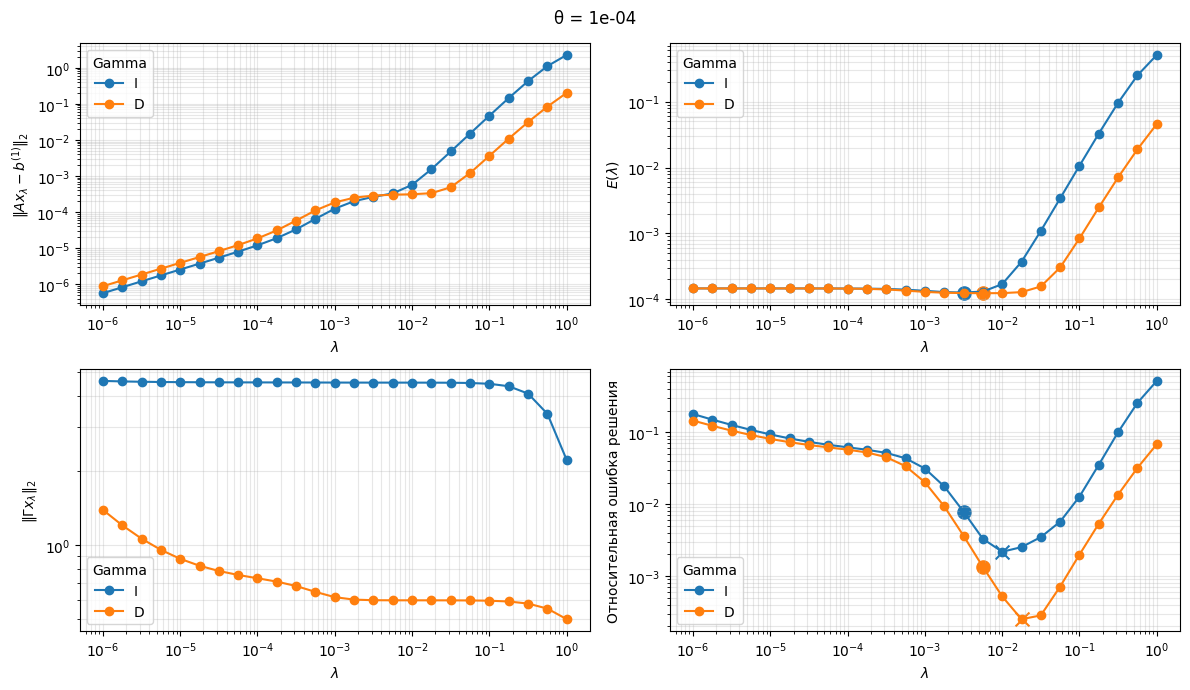

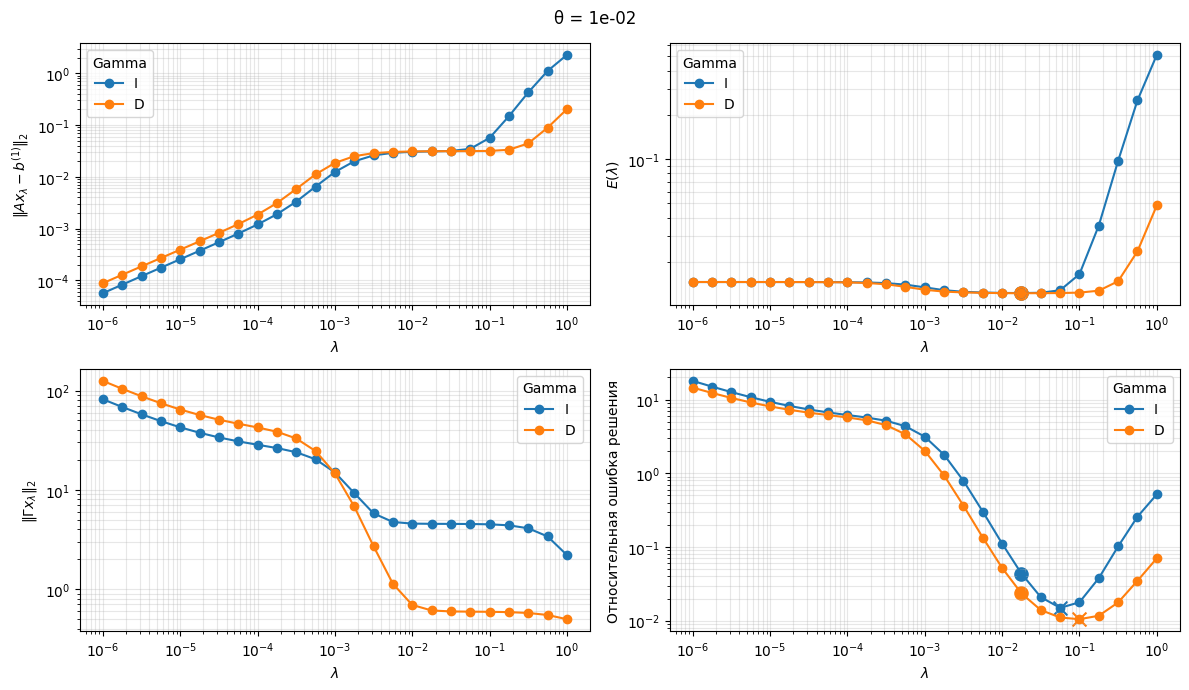

In [11]:
for i, theta in enumerate(thetas):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for j, name in enumerate(PENALTIES):
        color = f"C{j}"
        axes[0, 0].loglog(lambdas, residuals[i, j], "o-", color=color, label=name)
        axes[0, 1].loglog(lambdas, validation[i, j], "o-", color=color, label=name)
        axes[1, 0].loglog(lambdas, penalty_norms[i, j], "o-", color=color, label=name)
        axes[1, 1].loglog(lambdas, errors[i, j], "o-", color=color, label=name)
        selected = selected_idx[i, j]
        best = best_error_idx[i, j]
        axes[0, 1].scatter(
            lambdas[selected], validation[i, j, selected], s=90, color=color
        )
        axes[1, 1].scatter(lambdas[selected], errors[i, j, selected], s=90, color=color)
        axes[1, 1].scatter(
            lambdas[best], errors[i, j, best], marker="x", s=100, color=color
        )

    axes[0, 0].set_ylabel(r"$\|Ax_\lambda-b^{(1)}\|_2$")
    axes[0, 1].set_ylabel(r"$E(\lambda)$")
    axes[1, 0].set_ylabel(r"$\|\Gamma x_\lambda\|_2$")
    axes[1, 1].set_ylabel("Относительная ошибка решения")
    for ax in axes.flat:
        ax.set_xlabel(r"$\lambda$")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(title="Gamma")
    fig.suptitle(f"θ = {theta:.0e}")
    plt.tight_layout()
    plt.show()

Для наименьшей, выбранной по $E$ и наибольшей $\lambda$ сравним восстановленные сигналы с $x^*$. Масштаб по вертикали выбирается отдельно для каждой панели, чтобы сохранить видимость колебаний при малой регуляризации.

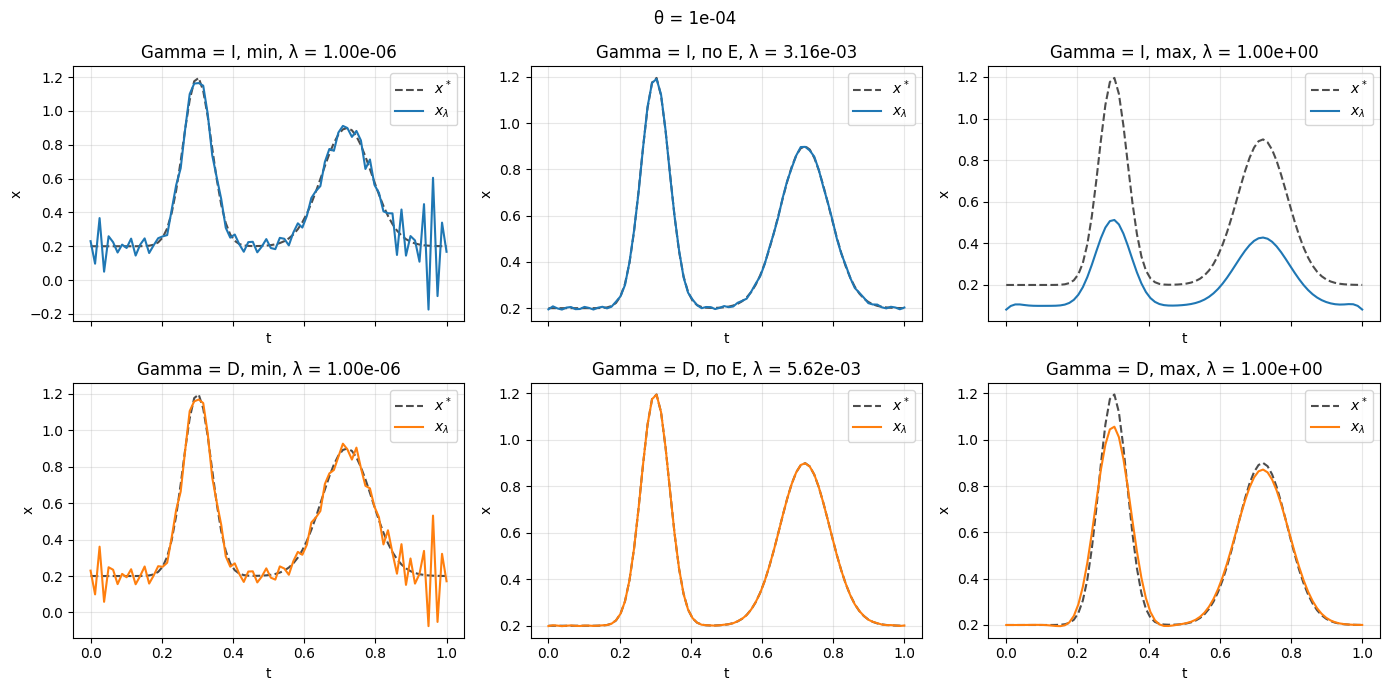

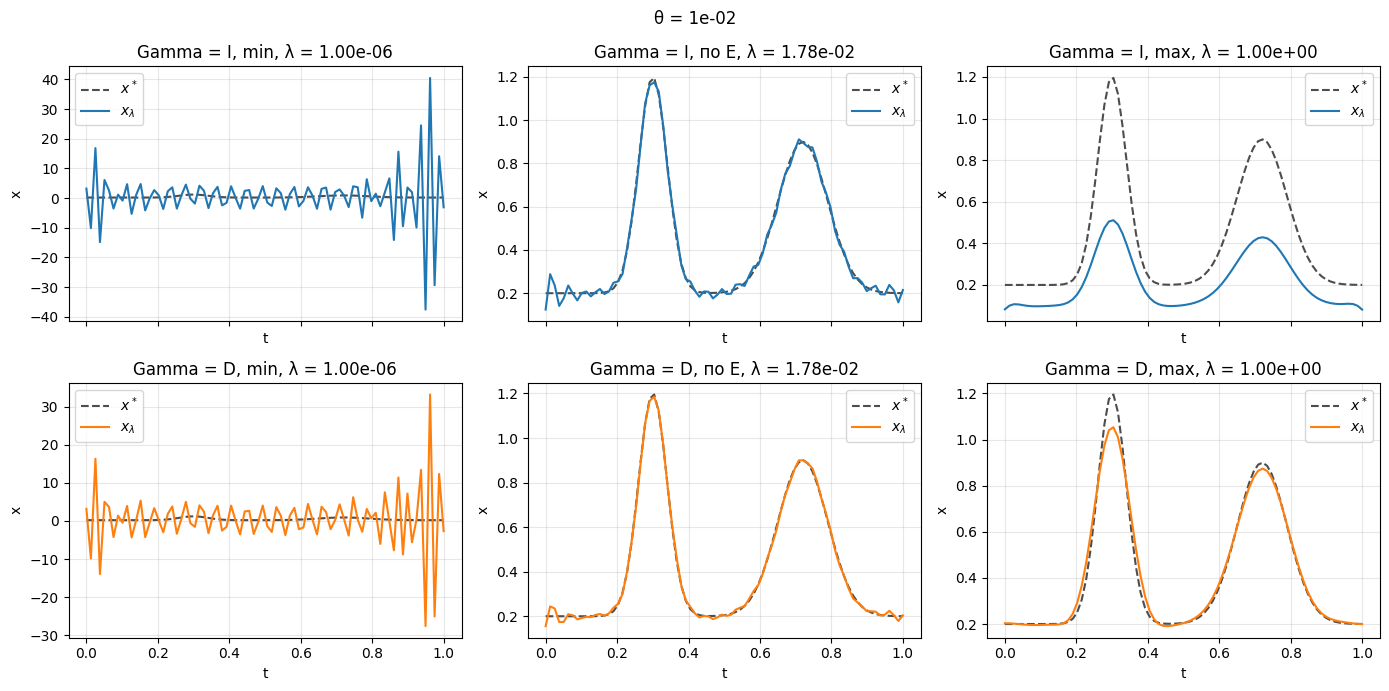

In [12]:
for i, theta in enumerate(thetas):
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
    for j, name in enumerate(PENALTIES):
        choices = (0, int(selected_idx[i, j]), len(lambdas) - 1)
        for col, (k, label) in enumerate(zip(choices, ("min", "по E", "max"))):
            axes[j, col].plot(t, x_star, "--", color="0.3", label=r"$x^*$")
            axes[j, col].plot(t, xs[i, j, k], color=f"C{j}", label=r"$x_\lambda$")
            axes[j, col].set_title(f"Gamma = {name}, {label}, λ = {lambdas[k]:.2e}")
            axes[j, col].set_xlabel("t")
            axes[j, col].set_ylabel("x")
            axes[j, col].grid(True, alpha=0.3)
            axes[j, col].legend()
    fig.suptitle(f"θ = {theta:.0e}")
    plt.tight_layout()
    plt.show()

In [13]:
rows = []
for i, theta in enumerate(thetas):
    for j, Gamma in enumerate(gammas):
        choices = (0, int(selected_idx[i, j]), len(lambdas) - 1)
        for k, label in zip(choices, ("min", "по E", "max")):
            A_reg, b_reg = tikhonov(A, b1[i], Gamma, x0, lambdas[k])
            rows.append(
                [
                    f"{theta:.0e}",
                    PENALTIES[j],
                    label,
                    f"{lambdas[k]:.6e}",
                    f"{chi_f(A_reg):.6e}",
                    f"{errors[i, j, k]:.6e}",
                ]
            )
print(
    text_table(
        ["theta", "Gamma", "выбор", "lambda", "chi_F(A_lambda)", "отн. ошибка"], rows
    )
)

theta  Gamma  выбор        lambda  chi_F(A_lambda)   отн. ошибка
-----  -----  -----  ------------  ---------------  ------------
1e-04      I    min  1.000000e-06     1.136611e+07  1.794830e-01
1e-04      I   по E  3.162278e-03     6.472889e+03  7.874826e-03
1e-04      I    max  1.000000e+00     8.181573e+01  5.179817e-01
1e-04      D    min  1.000000e-06     6.170011e+06  1.455652e-01
1e-04      D   по E  5.623413e-03     2.171654e+03  1.345152e-03
1e-04      D    max  1.000000e+00     9.947019e+01  6.827675e-02
1e-02      I    min  1.000000e-06     1.136611e+07  1.794796e+01
1e-02      I   по E  1.778279e-02     1.268112e+03  4.349761e-02
1e-02      I    max  1.000000e+00     8.181573e+01  5.182395e-01
1e-02      D    min  1.000000e-06     6.170011e+06  1.455653e+01
1e-02      D   по E  1.778279e-02     7.591178e+02  2.345138e-02
1e-02      D    max  1.000000e+00     9.947019e+01  7.033600e-02


### Вывод

При минимальной $\lambda=10^{-6}$ в решениях ещё заметны колебания. Относительные ошибки для штрафов $I$ и $D$ составляют примерно $0.179$ и $0.146$ при малом возмущении, $17.9$ и $14.6$ при большом.

Параметры, выбранные по $E$, подавляют колебания и сохраняют оба пика. Штраф $D$ лучше восстанавливает форму на этих данных. При $\theta=10^{-4}$ его ошибка $0.00135$ примерно в шесть раз меньше ошибки со штрафом $I$. При $\theta=10^{-2}$ ошибки равны $0.0235$ и $0.0435$.

При $\lambda=1$ штраф $I$ существенно уменьшает весь сигнал. Высота первого пика падает примерно с $1.20$ до $0.51$, второго с $0.90$ до $0.43$. Фон возле краёв уменьшается с $0.20$ примерно до $0.08$. Ошибка решения становится около $0.52$.

Штраф $D$ при той же $\lambda$ сохраняет фон около $0.20$ и сильнее сглаживает узкий первый пик. Его высота уменьшается примерно до $1.06$, высота второго до $0.87$. Между пиками сигнал становится более плавным. Ошибка составляет около $0.068$ при малом возмущении и $0.070$ при большом.

Улучшение обусловленности расширенной системы сопровождается изменением самой задачи. Например, при $\theta=10^{-4}$ и штрафе $I$ переход от выбранной $\lambda$ к 1 уменьшает $\chi_F(A_\lambda)$ с $6473$ до $81.8$, но увеличивает ошибку с $0.00787$ до $0.52$. Для $D$ показатель уменьшается с $2172$ до $99.5$, ошибка растёт с $0.00135$ до $0.068$.

Хорошая обусловленность помогает точнее решить регуляризованную задачу. Близость результата к $x^*$ также зависит от ошибок данных и смещения, которое вносит выбранный штраф. Излишне сильная регуляризация сглаживает полезные детали и снижает точность восстановления.